In [15]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

In [16]:
hip = Image.open('content/jednorozec.png').convert('RGBA')
arr = np.array(hip)

In [17]:
arr.shape

(1254, 1254, 4)

In [18]:
h, w, _ = arr.shape
print(h)
print(w)

1254
1254


Państwa zadaniem jest ustalenie, jak należy zmodyfikować fragment:

`hip_fragment = arr[h//2:h, 0:w//2]`

tak, aby kolejno wycinać również trzy pozostałe ćwiartki obrazu.
Proszę modyfikować kod i sprawdzać efekt, tak aby uzyskać kolejno:

1.	lewą górną ćwiartkę,
2.	prawą górną ćwiartkę,
3.	lewą dolną ćwiartkę,
4.	prawą dolną ćwiartkę.


In [19]:
hip_fragment = arr[h//2:h, 0:w//2]

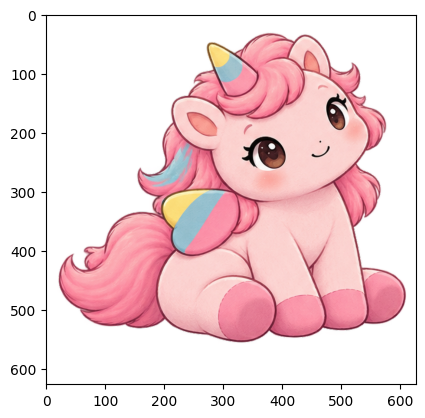

In [20]:
plt.imshow(hip_fragment)
#plt.axis('off')

In [21]:
# Tło, np. łąka
bg = Image.open('content/tlo_laka.png').convert('RGBA')

In [22]:
# =========================
# 2. Zamiana bieli na alfa
# =========================
arr = np.array(hip_fragment)

# Kanały RGB
rgb = arr[:, :, :3]

# Maska pikseli "prawie białych"
# Możesz zmieniać próg, np. 240, 245, 250
mask_white = np.all(rgb > 240, axis=2)

# Ustawienie przezroczystości:
# tam gdzie biało -> alfa = 0
arr[mask_white, 3] = 0

# Z powrotem do obrazu Pillow
hip_alpha = Image.fromarray(arr)

In [23]:
# =========================
# 3. Opcjonalne skalowanie Hipka
# =========================
scale = 0.9
new_size = (int(hip_alpha.width * scale), int(hip_alpha.height * scale))
hip_alpha = hip_alpha.resize(new_size)

In [24]:
# =========================
# 4. Nałożenie Hipka na tło
# =========================
# Pozycja lewego górnego rogu Hipka na tle
x = 420
y = 220

# Tworzymy przezroczystą warstwę o rozmiarze tła
layer = Image.new('RGBA', bg.size, (0, 0, 0, 0))

# Wklejamy Hipka na warstwę, używając jego kanału alfa
layer.paste(hip_alpha, (x, y), hip_alpha)

# Łączenie warstwy z tłem
result = Image.alpha_composite(bg, layer)


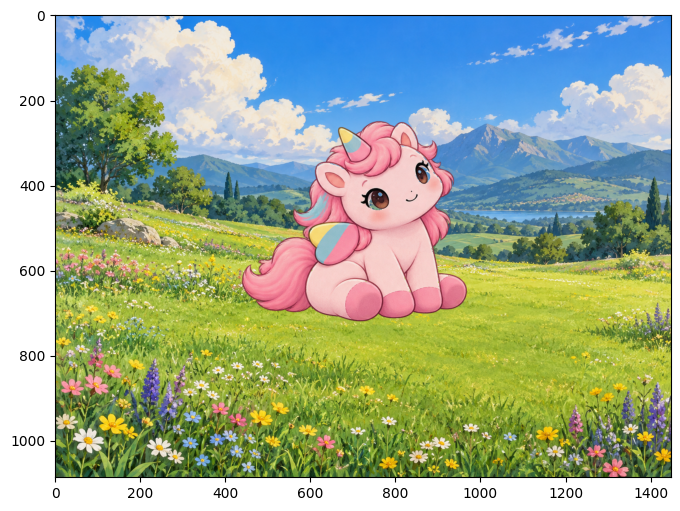

In [25]:
# =========================
# 5. Zapis i podgląd
# =========================
result.save('/content/hipek_na_tle.png')

plt.figure(figsize=(8, 6))
plt.imshow(result)
#plt.axis('off')
plt.show()